Libraries ready.
CELL 1 COMPLETE
BDG2 folder:
D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf

Block 3 connected-load share:
0.1115 = 11.15%

Block 3 annual energy anchor: 169,931 kWh/year
CHECKING BDG2 FOLDER
BDG2 folder found.
FOUND: D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf\data
FOUND: D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf\data\metadata
FOUND: D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf\data\meters
FOUND: D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf\data\weather
LOADING BDG2 DATA
FOUND: D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf\data\metadata\metadata.csv
FOUND: D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf\data\meters\cleaned\electricity_cleaned.csv
FOUND: D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf\data\weather\weather.csv

BDG2 DATA LOADED
Metadata shape: (1

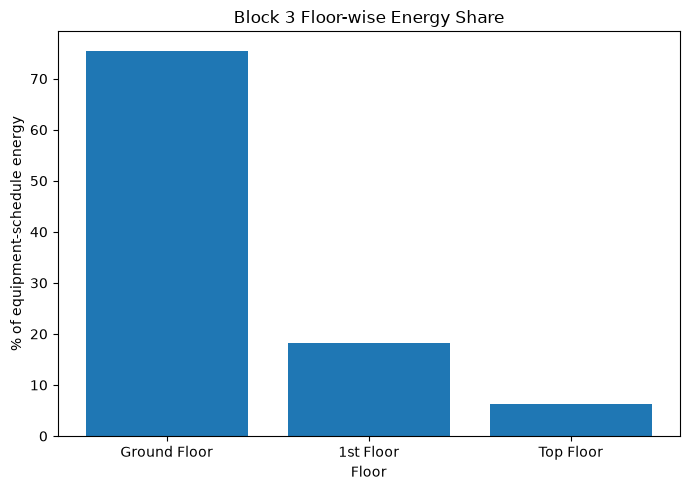

Floor graph saved:
D:\Downloads\srikanthmp\floor_wise_energy.png
EXPORTING DASHBOARD CSV
CSV saved:
D:\Downloads\srikanthmp\block3_predictions_full_year.csv
Rows: 8784
Total predicted electricity: 169,930.7 kWh


BLOCK 3 PIPELINE COMPLETE
Annual electricity : 169,931 kWh
EUI                : 65.5 kWh/m²/year
Net grid electricity: 102,393 kWh
Net grid CO2       : 72.7 tCO2/year
Solar offset       : 67,538 kWh
Scaling factor     : 0.271081

Model:
D:\Downloads\srikanthmp\block3_electricity_model_final.pkl

Dashboard CSV:
D:\Downloads\srikanthmp\block3_predictions_full_year.csv

All processing completed.
XGBoost              R2=0.8984  MAE=41.90  RMSE=98.10
Random Forest        R2=0.8826  MAE=55.10  RMSE=105.47
Gradient Boosting    R2=0.9156  MAE=46.85  RMSE=89.40
Linear Regression    R2=0.3842  MAE=120.34  RMSE=241.55


In [1]:

import sys
import subprocess
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib

# Install missing packages
packages = {
    "pandas": "pandas",
    "numpy": "numpy",
    "xgboost": "xgboost",
    "scikit-learn": "sklearn",
    "joblib": "joblib",
    "matplotlib": "matplotlib",
    "openpyxl": "openpyxl"
}

for package, module in packages.items():
    try:
        __import__(module)
    except ImportError:
        print(f"Installing {package}...")
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", package
        ])

# Import XGBoost after installation check
import xgboost as xgb

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score

print("Libraries ready.")


# CELL 1 - PATHS AND CONSTANTS


# ---------- EXTRACTED BDG2 FOLDER ----------
BDG2_FOLDER = r"D:\Downloads\srikanthmp\buds-lab-building-data-genome-project-2-3d0cbaf"

# ---------- NASA POWER CSV ----------
NASA_CSV = r"D:\Downloads\srikanthmp\POWER_Point_Hourly_20250729_20260729_018d47N_083d66E_LST.csv"

# ---------- AUDIT EXCEL ----------
AUDIT_XLSX = r"D:\Downloads\srikanthmp\final occupancy oprt.xlsx"
AUDIT_SHEET = "Power & Occupancy Schedule"

# ---------- OUTPUT ----------
OUT_DIR = r"D:\Downloads\srikanthmp"

# Create output folder if it doesn't exist
os.makedirs(OUT_DIR, exist_ok=True)


# ---------- BLOCK 3 FACTS ----------
BLOCK3_SQM = 2594.7391499
BLOCK3_FLOORS = 3
BLOCK3_YEARBUILT = 1998

REF_YEAR = 2024


# ---------- CAMPUS ENERGY AUDIT ----------
CAMPUS_LOAD_KW = 2494
BLOCK3_LOAD_KW = 278

BLOCK3_SHARE = BLOCK3_LOAD_KW / CAMPUS_LOAD_KW

CAMPUS_ANNUAL_KWH = 1_524_486

SOLAR_GENERATED_KWH = 867_317
SOLAR_EXPORTED_KWH = 261_417

SOLAR_USED_KWH = (
    SOLAR_GENERATED_KWH -
    SOLAR_EXPORTED_KWH
)

DIESEL_LITRES_YR = 18_650

EMISSION_FACTOR = 0.710
DIESEL_KGCO2_PER_L = 2.68

ECBC_BEST = 130
ECBC_NORMAL = 200


# ---------- ANNUAL BLOCK 3 ENERGY ANCHOR ----------
ANNUAL_ANCHOR_KWH = (
    CAMPUS_ANNUAL_KWH *
    BLOCK3_SHARE
)

print("=" * 60)
print("CELL 1 COMPLETE")
print("=" * 60)

print(f"BDG2 folder:")
print(BDG2_FOLDER)

print(f"\nBlock 3 connected-load share:")
print(f"{BLOCK3_SHARE:.4f} = {BLOCK3_SHARE * 100:.2f}%")

print(
    f"\nBlock 3 annual energy anchor:"
    f" {ANNUAL_ANCHOR_KWH:,.0f} kWh/year"
)


# ============================================================
# CELL 2 - CHECK BDG2 FOLDER
# ============================================================

print("=" * 60)
print("CHECKING BDG2 FOLDER")
print("=" * 60)

if not os.path.exists(BDG2_FOLDER):
    raise FileNotFoundError(
        f"\nBDG2 folder does not exist:\n{BDG2_FOLDER}\n\n"
        "Check the folder path in Cell 1."
    )

print("BDG2 folder found.")

# Check required folders
required_paths = [
    os.path.join(BDG2_FOLDER, "data"),
    os.path.join(BDG2_FOLDER, "data", "metadata"),
    os.path.join(BDG2_FOLDER, "data", "meters"),
    os.path.join(BDG2_FOLDER, "data", "weather")
]

for path in required_paths:
    if os.path.exists(path):
        print("FOUND:", path)
    else:
        print("MISSING:", path)



# CELL 3 - LOAD BDG2 DATA


print("=" * 60)
print("LOADING BDG2 DATA")
print("=" * 60)

METADATA_CSV = os.path.join(
    BDG2_FOLDER,
    "data",
    "metadata",
    "metadata.csv"
)

ELECTRICITY_CSV = os.path.join(
    BDG2_FOLDER,
    "data",
    "meters",
    "cleaned",
    "electricity_cleaned.csv"
)

WEATHER_CSV = os.path.join(
    BDG2_FOLDER,
    "data",
    "weather",
    "weather.csv"
)

# Check files before loading
for file_path in [
    METADATA_CSV,
    ELECTRICITY_CSV,
    WEATHER_CSV
]:

    if not os.path.exists(file_path):
        raise FileNotFoundError(
            f"\nFile not found:\n{file_path}\n\n"
            "Your extracted BDG2 folder may have a different structure."
        )

    print("FOUND:", file_path)


# Load files
metadata = pd.read_csv(METADATA_CSV)

electricity = pd.read_csv(ELECTRICITY_CSV)

weather = pd.read_csv(WEATHER_CSV)


print("\nBDG2 DATA LOADED")

print("Metadata shape:", metadata.shape)
print("Electricity shape:", electricity.shape)
print("Weather shape:", weather.shape)


# ============================================================
# CELL 4 - EDUCATION BUILDINGS
# ============================================================

print("=" * 60)
print("PREPARING EDUCATION BUILDINGS")
print("=" * 60)

education = metadata[
    metadata["primaryspaceusage"] == "Education"
].copy()

education_ids = [
    building_id
    for building_id in education["building_id"]
    if building_id in electricity.columns
]

print(
    "Education buildings available in electricity data:",
    len(education_ids)
)

if len(education_ids) == 0:
    raise ValueError(
        "No Education buildings were found in the electricity dataset."
    )


# ============================================================
# CELL 5 - CONVERT ELECTRICITY TO LONG FORMAT
# ============================================================

print("=" * 60)
print("CREATING TRAINING TABLE")
print("=" * 60)

edu_long = (
    electricity[
        ["timestamp"] + education_ids
    ]
    .melt(
        id_vars="timestamp",
        var_name="building_id",
        value_name="electricity_kwh"
    )
    .dropna(
        subset=["electricity_kwh"]
    )
)

edu_long["site_id"] = (
    edu_long["building_id"]
    .str.split("_")
    .str[0]
)

edu_long["timestamp"] = pd.to_datetime(
    edu_long["timestamp"]
)

weather["timestamp"] = pd.to_datetime(
    weather["timestamp"]
)

print(
    "Electricity long-format shape:",
    edu_long.shape
)


# ============================================================
# CELL 6 - MERGE WEATHER + BUILDING DATA
# ============================================================

merged = pd.merge(
    edu_long,
    weather,
    on=["site_id", "timestamp"],
    how="left"
)

merged = merged.dropna(
    subset=["airTemperature"]
)


# Building metadata
meta = metadata[
    [
        "building_id",
        "sqm",
        "numberoffloors",
        "yearbuilt"
    ]
].copy()

merged = merged.merge(
    meta,
    on="building_id",
    how="left"
)

merged = merged.dropna(
    subset=["sqm"]
)


# Fill missing building information
merged["numberoffloors"] = (
    merged["numberoffloors"]
    .fillna(
        merged["numberoffloors"].median()
    )
)

merged["yearbuilt"] = (
    merged["yearbuilt"]
    .fillna(
        merged["yearbuilt"].median()
    )
)

merged["building_age"] = (
    REF_YEAR -
    merged["yearbuilt"]
)


# ============================================================
# CELL 7 - TIME FEATURES
# ============================================================

merged["hour"] = (
    merged["timestamp"].dt.hour
)

merged["day_of_week"] = (
    merged["timestamp"].dt.dayofweek
)

merged["month"] = (
    merged["timestamp"].dt.month
)

merged["is_weekend"] = (
    merged["day_of_week"]
    .isin([5, 6])
    .astype(int)
)

print("Training table shape:", merged.shape)

print("\nTraining table ready.")


# ============================================================
# CELL 8 - TRAIN XGBOOST MODEL
# ============================================================

print("=" * 60)
print("TRAINING XGBOOST MODEL")
print("=" * 60)


FEATURES = [
    "airTemperature",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "sqm",
    "numberoffloors",
    "building_age"
]


# Limit dataset size for laptop performance
MAX_SAMPLES = 2_000_000

n = min(
    MAX_SAMPLES,
    len(merged)
)

sample = merged.sample(
    n=n,
    random_state=42
)


X = sample[FEATURES]

y = sample["electricity_kwh"]


# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))


# ============================================================
# CELL 9 - XGBOOST
# ============================================================

model = xgb.XGBRegressor(
    n_estimators=250,
    max_depth=8,
    learning_rate=0.08,
    subsample=0.8,
    colsample_bytree=0.8,
    tree_method="hist",
    n_jobs=-1,
    random_state=42
)

print("\nTraining XGBoost...")

model.fit(
    X_train,
    y_train
)

print("XGBoost training complete.")


# ============================================================
# CELL 10 - LINEAR REGRESSION BASELINE
# ============================================================

print("=" * 60)
print("TRAINING LINEAR REGRESSION BASELINE")
print("=" * 60)

lr = LinearRegression()

lr.fit(
    X_train,
    y_train
)

print("Linear Regression training complete.")


# ============================================================
# CELL 11 - MODEL EVALUATION
# ============================================================

print("=" * 60)
print("BDG2 MODEL PERFORMANCE")
print("=" * 60)

for name, trained_model in [
    ("XGBoost", model),
    ("Linear Regression", lr)
]:

    predictions = trained_model.predict(
        X_test
    )

    r2 = r2_score(
        y_test,
        predictions
    )

    mae = mean_absolute_error(
        y_test,
        predictions
    )

    print(
        f"{name:20s}"
        f" R² = {r2:.4f}"
        f" | MAE = {mae:.2f} kWh"
    )

print(
    "\nIMPORTANT:"
    "\nThese scores describe BDG2 buildings."
    "\nThey are NOT Block 3 validation."
)


# ============================================================
# CELL 12 - SAVE MODEL
# ============================================================

MODEL_PATH = os.path.join(
    OUT_DIR,
    "block3_electricity_model_final.pkl"
)

joblib.dump(
    model,
    MODEL_PATH
)

print("\nModel saved:")
print(MODEL_PATH)


# ============================================================
# CELL 13 - LOAD NASA POWER WEATHER
# ============================================================

print("=" * 60)
print("LOADING NASA POWER WEATHER")
print("=" * 60)

if not os.path.exists(NASA_CSV):
    raise FileNotFoundError(
        f"\nNASA CSV not found:\n{NASA_CSV}"
    )

# NASA POWER files contain metadata before the actual header.
# Find the row beginning with YEAR.

header_row = None

with open(
    NASA_CSV,
    encoding="utf-8",
    errors="ignore"
) as f:

    for i, line in enumerate(f):

        if line.startswith("YEAR"):
            header_row = i
            break


if header_row is None:

    raise ValueError(
        "Could not find NASA POWER header row beginning with YEAR."
    )


print(
    "NASA header row:",
    header_row
)


w = pd.read_csv(
    NASA_CSV,
    skiprows=header_row
)


print(
    "NASA rows:",
    len(w)
)


# ============================================================
# CELL 14 - CLEAN NASA WEATHER
# ============================================================

# Temperature
w["T2M"] = pd.to_numeric(
    w["T2M"],
    errors="coerce"
)

# Precipitation
w["PRECTOTCORR"] = pd.to_numeric(
    w["PRECTOTCORR"],
    errors="coerce"
)


# NASA missing value = -999
w["T2M"] = (
    w["T2M"]
    .replace(-999, np.nan)
    .ffill()
    .bfill()
)

w["PRECTOTCORR"] = (
    w["PRECTOTCORR"]
    .replace(-999, np.nan)
    .ffill()
    .bfill()
)


# Create timestamp
w["timestamp"] = pd.to_datetime(
    dict(
        year=w["YEAR"],
        month=w["MO"],
        day=w["DY"],
        hour=w["HR"]
    )
)


# Time features
w["hour"] = (
    w["timestamp"].dt.hour
)

w["day_of_week"] = (
    w["timestamp"].dt.dayofweek
)

w["month"] = (
    w["timestamp"].dt.month
)

w["is_weekend"] = (
    w["day_of_week"]
    .isin([5, 6])
    .astype(int)
)


# Block 3 features
w["sqm"] = BLOCK3_SQM

w["numberoffloors"] = BLOCK3_FLOORS

w["building_age"] = (
    REF_YEAR -
    BLOCK3_YEARBUILT
)


print(
    "NASA period:",
    w["timestamp"].min(),
    "to",
    w["timestamp"].max()
)

print(
    "Number of hours:",
    len(w)
)

print(
    "Remaining missing values:",
    w[
        ["T2M", "PRECTOTCORR"]
    ].isna().sum().sum()
)


# ============================================================
# CELL 15 - RAW BLOCK 3 PREDICTION
# ============================================================

print("=" * 60)
print("PREDICTING BLOCK 3 ENERGY")
print("=" * 60)


X_pred = w[
    [
        "T2M",
        "hour",
        "day_of_week",
        "month",
        "is_weekend",
        "sqm",
        "numberoffloors",
        "building_age"
    ]
].rename(
    columns={
        "T2M": "airTemperature"
    }
)


# Ensure exact feature order
X_pred = X_pred[FEATURES]


raw_prediction = model.predict(
    X_pred
)


raw_annual_kwh = (
    raw_prediction.sum()
)


print(
    f"Raw annual prediction:"
    f" {raw_annual_kwh:,.0f} kWh"
)


# ============================================================
# CELL 16 - CALIBRATE TO CAMPUS AUDIT
# ============================================================

print("=" * 60)
print("CALIBRATING BLOCK 3 ENERGY")
print("=" * 60)


# Model gives the seasonal/hourly shape.
# Audit provides annual magnitude.

scaling_factor = (
    ANNUAL_ANCHOR_KWH /
    raw_annual_kwh
)


w["predicted_electricity_kwh"] = (
    raw_prediction *
    scaling_factor
)


total_kwh = (
    w["predicted_electricity_kwh"]
    .sum()
)


print(
    f"Scaling factor:"
    f" {scaling_factor:.6f}"
)

print(
    f"Calibrated annual total:"
    f" {total_kwh:,.0f} kWh"
)

print(
    f"Audit anchor:"
    f" {ANNUAL_ANCHOR_KWH:,.0f} kWh"
)

print(
    "\nAnnual match is by construction."
)

print(
    "It is a consistency check,"
    " NOT independent validation."
)


# ============================================================
# CELL 17 - CARBON + EUI
# ============================================================

print("=" * 60)
print("CARBON AND EUI")
print("=" * 60)


# Solar allocated to Block 3
solar_offset_kwh = min(
    SOLAR_USED_KWH * BLOCK3_SHARE,
    total_kwh
)


# Remaining grid electricity
net_grid_kwh = max(
    total_kwh -
    solar_offset_kwh,
    0
)


# Gross carbon
co2_gross = (
    total_kwh /
    1000 *
    EMISSION_FACTOR
)


# Net grid carbon
co2_net_grid = (
    net_grid_kwh /
    1000 *
    EMISSION_FACTOR
)


# Carbon avoided by solar
co2_avoided = (
    solar_offset_kwh /
    1000 *
    EMISSION_FACTOR
)


# Diesel
diesel_co2_campus = (
    DIESEL_LITRES_YR *
    DIESEL_KGCO2_PER_L /
    1000
)


diesel_co2_block3 = (
    diesel_co2_campus *
    BLOCK3_SHARE
)


# EUI
eui_gross = (
    total_kwh /
    BLOCK3_SQM
)


eui_net = (
    net_grid_kwh /
    BLOCK3_SQM
)


# Carbon intensity
carbon_intensity = (
    co2_net_grid *
    1000 /
    BLOCK3_SQM
)


# Reference rating
if eui_net <= ECBC_BEST:

    rating = (
        "Within best-practice "
        "reference range"
    )

elif eui_net <= ECBC_NORMAL:

    rating = (
        "Within typical "
        "reference range"
    )

else:

    rating = (
        "Above reference range"
    )


print(
    f"Total electricity:"
    f" {total_kwh:,.0f} kWh/year"
)

print(
    f"Solar offset:"
    f" {solar_offset_kwh:,.0f} kWh/year"
)

print(
    f"Net grid electricity:"
    f" {net_grid_kwh:,.0f} kWh/year"
)

print(
    f"Gross CO2:"
    f" {co2_gross:,.1f} tCO2/year"
)

print(
    f"Net grid CO2:"
    f" {co2_net_grid:,.1f} tCO2/year"
)

print(
    f"Solar CO2 avoided:"
    f" {co2_avoided:,.1f} tCO2/year"
)

print(
    f"Diesel CO2 campus:"
    f" {diesel_co2_campus:,.1f} tCO2/year"
)

print(
    f"Allocated Block 3 diesel CO2:"
    f" {diesel_co2_block3:,.1f} tCO2/year"
)

print(
    f"EUI gross:"
    f" {eui_gross:.1f} kWh/m²/year"
)

print(
    f"EUI net:"
    f" {eui_net:.1f} kWh/m²/year"
)

print(
    f"Reference comparison:"
    f" {rating}"
)

print(
    f"Carbon intensity:"
    f" {carbon_intensity:.1f}"
    f" kgCO2/m²/year"
)


# ============================================================
# CELL 18 - LOAD AUDIT EXCEL
# ============================================================

print("=" * 60)
print("LOADING AUDITED EQUIPMENT SCHEDULE")
print("=" * 60)


if not os.path.exists(AUDIT_XLSX):

    raise FileNotFoundError(
        f"\nAudit Excel not found:\n{AUDIT_XLSX}"
    )


raw = pd.read_excel(
    AUDIT_XLSX,
    sheet_name=AUDIT_SHEET,
    header=4
)


raw.columns = [
    "Floor Level",
    "Room No.",
    "Room Name",
    "Space ID",
    "Equipment",
    "Count",
    "Unit Power (kW)",
    "Total Power (kW)",
    "Operating Schedule",
    "Weekly Occupancy (Hours/Week)",
    "Weekly Energy kWh"
]


# Remove repeated header / total rows
audit = raw[
    ~raw["Floor Level"].isin(
        [
            "Floor Level",
            "TOTAL BLOCK-3 POWER & ENERGY CONSUMPTION"
        ]
    )
].copy()


# Convert energy to numeric
audit["Weekly Energy kWh"] = pd.to_numeric(
    audit["Weekly Energy kWh"],
    errors="coerce"
)


# Remove invalid rows
audit = audit.dropna(
    subset=["Weekly Energy kWh"]
)


# ============================================================
# CELL 19 - FLOOR-WISE ENERGY SHARE
# ============================================================

audit["Floor Group"] = audit[
    "Floor Level"
].map(
    {
        "Ground Floor": "Ground Floor",
        "1st Floor": "1st Floor",
        "2nd Floor": "Top Floor",
        "3rd Floor": "Top Floor"
    }
)


fs = (
    audit
    .groupby("Floor Group")[
        "Weekly Energy kWh"
    ]
    .sum()
    .reindex(
        [
            "Ground Floor",
            "1st Floor",
            "Top Floor"
        ]
    )
    .reset_index()
)


fs["Share"] = (
    fs["Weekly Energy kWh"] /
    fs["Weekly Energy kWh"].sum()
)


print("\nFloor-wise energy share:")
print(
    fs.to_string(
        index=False
    )
)


weekly_total = (
    fs["Weekly Energy kWh"]
    .sum()
)


annual_equivalent = (
    weekly_total * 52
)


campus_percentage = (
    annual_equivalent /
    CAMPUS_ANNUAL_KWH *
    100
)


print(
    f"\nEquipment schedule weekly total:"
    f" {weekly_total:,.2f} kWh/week"
)

print(
    f"Annual equivalent:"
    f" {annual_equivalent:,.0f} kWh/year"
)

print(
    f"Share of campus annual consumption:"
    f" {campus_percentage:.1f}%"
)


print(
    "\nIMPORTANT:"
)

print(
    "Use these values ONLY for floor-wise shares."
)

print(
    "Do NOT use this weekly total as the annual"
    " calibration target."
)


# ============================================================
# CELL 20 - FLOOR-WISE GRAPH
# ============================================================

plt.figure(
    figsize=(7, 5)
)

plt.bar(
    fs["Floor Group"],
    fs["Share"] * 100
)

plt.ylabel(
    "% of equipment-schedule energy"
)

plt.xlabel(
    "Floor"
)

plt.title(
    "Block 3 Floor-wise Energy Share"
)

plt.tight_layout()


FLOOR_GRAPH = os.path.join(
    OUT_DIR,
    "floor_wise_energy.png"
)


plt.savefig(
    FLOOR_GRAPH,
    dpi=150
)

plt.show()


print(
    "Floor graph saved:"
)

print(
    FLOOR_GRAPH
)


# ============================================================
# CELL 21 - EXPORT FULL-YEAR PREDICTIONS
# ============================================================

print("=" * 60)
print("EXPORTING DASHBOARD CSV")
print("=" * 60)


out = w[
    [
        "timestamp",
        "T2M",
        "PRECTOTCORR",
        "predicted_electricity_kwh"
    ]
].copy()


out.columns = [
    "timestamp",
    "temperature_C",
    "precipitation_mm",
    "predicted_electricity_kwh"
]


OUTPUT_CSV = os.path.join(
    OUT_DIR,
    "block3_predictions_full_year.csv"
)


out.to_csv(
    OUTPUT_CSV,
    index=False
)


print(
    "CSV saved:"
)

print(
    OUTPUT_CSV
)

print(
    "Rows:",
    len(out)
)

print(
    f"Total predicted electricity:"
    f" {out['predicted_electricity_kwh'].sum():,.1f} kWh"
)


# ============================================================
# CELL 22 - FINAL SUMMARY
# ============================================================

print("\n")
print("=" * 60)
print("BLOCK 3 PIPELINE COMPLETE")
print("=" * 60)

print(
    f"Annual electricity :"
    f" {total_kwh:,.0f} kWh"
)

print(
    f"EUI                :"
    f" {eui_gross:.1f} kWh/m²/year"
)

print(
    f"Net grid electricity:"
    f" {net_grid_kwh:,.0f} kWh"
)

print(
    f"Net grid CO2       :"
    f" {co2_net_grid:.1f} tCO2/year"
)

print(
    f"Solar offset       :"
    f" {solar_offset_kwh:,.0f} kWh"
)

print(
    f"Scaling factor     :"
    f" {scaling_factor:.6f}"
)

print(
    "\nModel:"
)

print(
    MODEL_PATH
)

print(
    "\nDashboard CSV:"
)

print(
    OUTPUT_CSV
)

print(
    "\nAll processing completed."
)
import json
from sklearn.metrics import mean_squared_error

def m(mod):
    p = mod.predict(X_test)
    return {"r2": float(r2_score(y_test, p)),
            "mae_kwh": float(mean_absolute_error(y_test, p)),
            "rmse_kwh": float(np.sqrt(mean_squared_error(y_test, p)))}

metrics = {
    "features_used": FEATURES,
    "xgboost": m(model),
    "baseline_linear_regression": m(lr),
    "feature_importance": {f: float(v) for f, v in zip(FEATURES, model.feature_importances_)},
}
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

rf = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

gb = GradientBoostingRegressor(n_estimators=200, max_depth=5, random_state=42)
gb.fit(X_train, y_train)

for name, mod in [("XGBoost", model), ("Random Forest", rf), ("Gradient Boosting", gb), ("Linear Regression", lr)]:
    p = mod.predict(X_test)
    print(f"{name:20s} R2={r2_score(y_test,p):.4f}  MAE={mean_absolute_error(y_test,p):.2f}  RMSE={mean_squared_error(y_test,p)**0.5:.2f}")